# Квартиры Астаны: описательный анализ мартовских данных

**Обновление после обучения.** Изучаем распределение цены, различия между районами, связь цены с площадью и корреляции числовых признаков в отдельно подготовленной мартовской выборке.

Источник — исходный CSV Turarr из [Astana Real Estate Dataset](https://www.kaggle.com/datasets/turarr/astana-real-estate-dataset), адаптированный отдельно от подготовленного автором CSV. **Конец марта 2026 года — период, заявленный автором набора. Дат сбора по отдельным строкам нет.** Даты публикации и скачивания не заменяют даты наблюдений. Происхождение и контрольная сумма закреплены в `data/turarr_march_2026.source.json`.

Это **цены предложения**, а не цены сделок или оценка рынка на сегодня. Данные не перезаписываются, пропуски не заполняются, модели не обучаются. Под каждым из четырёх графиков вывод вычисляется из загруженных данных.

**Граница интерпретации:** EDA выполнен после обучения и охватывает все очищенные строки, включая test. Его результаты описывают выборку и не используются для выбора модели, признаков, гиперпараметров или изменения уже выполненного разбиения. Новые гипотезы потребуют независимой проверки.

**Приложение сохраняет январскую модель.** Этот ноутбук читает отдельный мартовский CSV из `data/processed/march_2026` и не переключает активную модель или январские данные. Мартовская модель проверена отдельно; этот EDA описывает данные после проверки.


## Как повторить анализ

Откройте ноутбук из папки проекта или `notebooks/`, выберите Python из `.venv` и выполните **Restart Kernel and Run All Cells**. Перед первым запуском установите зависимости из `requirements.txt`.

Графики сохраняются в `reports/figures/eda_*.png`, численные результаты — в `reports/eda_summary.json`. Используются восемь входных признаков сохранённой модели. Здесь описывается вся подготовленная мартовская выборка, включая test; оценка качества модели и выбор её параметров в этом ноутбуке не выполняются.

Оригинальный январский ноутбук сохранён в `notebooks/archive/01_eda_january_2026.ipynb`; январские отчёты и графики — в `reports/archive/january_2026`.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, NullFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

%matplotlib inline

# Ноутбук работает из корня проекта и из notebooks/ без путей с именем пользователя.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "config.py").is_file() and (path / "data").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта или notebooks/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from config import FIGURES_DIR, REPORTS_DIR

# Мартовский набор анализируется отдельно; приложение остаётся на январской модели.
CLEAN_LISTINGS_PATH = project_root / "data" / "processed" / "march_2026" / "listings_clean.csv"
CLEANING_REPORT_PATH = project_root / "reports" / "march_update" / "cleaning_report.json"

FEATURES = ["district", "area", "rooms", "floor", "total_floors", "year_built", "building_type", "condition"]
NUMERIC = ["price", "area", "rooms", "floor", "total_floors", "year_built"]
LABELS = {"price": "Цена", "area": "Площадь", "rooms": "Комнаты", "floor": "Этаж", "total_floors": "Этажность", "year_built": "Год постройки"}
TEAL = "#167D9A"
ORANGE = "#D77732"
PRICE_TICKS = [5, 10, 20, 50, 100, 200, 500, 1500]

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans", rc={
    "figure.dpi": 110, "savefig.dpi": 180,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "grid.alpha": 0.25,
})
pd.set_option("display.max_columns", 12)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)


def ru_number(value: float, decimals: int = 1) -> str:
    return f"{value:,.{decimals}f}".replace(",", " ").replace(".", ",")


def price_tick(value: float, position: float) -> str:
    return ru_number(value, 0)


def finish_plot(figure: Figure, filename: str, conclusion: str) -> None:
    """Сохраняет график и выводит одну строку вывода под ним."""
    figure.savefig(FIGURES_DIR / filename, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(figure)
    display(Markdown(f"**Вывод:** {conclusion}"))

## 1. Загрузка и проверка данных

Сверяем CSV с отчётом очистки по числу строк и SHA-256. Это помогает заметить случайную подмену файла. Проверки ниже проверяют техническую согласованность, но не доказывают достоверность каждого объявления.

In [2]:
if not CLEAN_LISTINGS_PATH.is_file():
    raise FileNotFoundError("Сначала подготовьте отдельные мартовские данные через march_data.py.")
input_hash = hashlib.sha256(CLEAN_LISTINGS_PATH.read_bytes()).hexdigest()
cleaning_report = json.loads(CLEANING_REPORT_PATH.read_text(encoding="utf-8"))
if input_hash != cleaning_report["output_sha256"]:
    raise ValueError("CSV не совпадает с отчётом очистки. Проверьте мартовскую версию данных и её отчёт.")

source_metadata_path = project_root / "data" / "turarr_march_2026.source.json"
source_metadata = json.loads(source_metadata_path.read_text(encoding="utf-8"))
if cleaning_report.get("input_sha256") != source_metadata["sha256"]:
    raise ValueError("Мартовский CSV не относится к закреплённому мартовскому исходнику Turarr.")
declared_period = "2026-03"
declared_period_label = "Конец марта 2026 года (период заявлен автором набора)"

df = pd.read_csv(CLEAN_LISTINGS_PATH, encoding="utf-8-sig")
if len(df) != cleaning_report["rows_after"] or df.empty:
    raise ValueError("Число строк не совпадает с отчётом очистки.")
if not set(FEATURES + ["price", "collected_at"]).issubset(df.columns):
    raise ValueError("В очищенном CSV не хватает колонок для анализа.")
if not (df["price"].gt(0).all() and df["area"].gt(0).all()):
    raise ValueError("Для логарифмической шкалы цена и площадь должны быть положительными.")

n_rows = len(df)
prices_mln = df["price"] / 1_000_000
price_stats = {
    "min": float(df["price"].min()), "median": float(df["price"].median()),
    "mean": float(df["price"].mean()), "p95": float(df["price"].quantile(0.95)),
    "p99": float(df["price"].quantile(0.99)), "max": float(df["price"].max()),
}
# Публикация и скачивание не являются датой сбора отдельных объявлений.
collection_dates = df["collected_at"].astype("string").str.slice(0, 10).dropna()
collected_date_min = str(collection_dates.min()) if not collection_dates.empty else None
collected_date_max = str(collection_dates.max()) if not collection_dates.empty else None
collection_description = (
    f"Даты по строкам: **{collected_date_min} — {collected_date_max}**."
    if not collection_dates.empty else
    "**Дат сбора по строкам нет.** Даты публикации и скачивания не подставляются."
)
display(Markdown(
    f"Загружено **{ru_number(n_rows, 0)} объявлений**, **{len(df.columns)} колонок**. "
    f"Период: **{declared_period_label}**. {collection_description}"
))
display(pd.DataFrame({
    "Показатель": ["Минимум", "Медиана", "Среднее", "95-й процентиль", "99-й процентиль", "Максимум"],
    "Цена, млн ₸": [price_stats[key] / 1_000_000 for key in ("min", "median", "mean", "p95", "p99", "max")],
}).round(2))

Загружено **3 759 объявлений**, **14 колонок**. Период: **Конец марта 2026 года (период заявлен автором набора)**. **Дат сбора по строкам нет.** Даты публикации и скачивания не подставляются.

,Показатель,"Цена, млн ₸"
0,Минимум,3.50
1,Медиана,36.00
2,Среднее,45.25
3,95-й процентиль,102.00
4,99-й процентиль,174.68
5,Максимум,640.00


## 2. Пропуски

Для сводной таблицы используем восемь входных признаков сохранённой модели. В корреляциях пропуски исключаются только для соответствующей пары колонок. Ноутбук не заполняет отсутствующие значения; обученный пайплайн обрабатывает их отдельно при прогнозировании.


In [3]:
missing = pd.DataFrame({
    "Пропусков": df[FEATURES].isna().sum(),
    "Доля, %": df[FEATURES].isna().mean() * 100,
}).sort_values("Пропусков", ascending=False)
missing.index.name = "Признак"
display(missing.round(2))
display(Markdown(
    f"Состояние квартиры отсутствует у **{ru_number(missing.loc['condition', 'Доля, %'])}%** "
    "объявлений: это ограничивает описание различий по состоянию квартиры."
))

,Пропусков,"Доля, %"
Признак,,
condition,1961,52.17
building_type,228,6.07
total_floors,165,4.39
district,132,3.51
floor,44,1.17
area,0,0.00
rooms,0,0.00
year_built,0,0.00


Состояние квартиры отсутствует у **52,2%** объявлений: это ограничивает описание различий по состоянию квартиры.

## 3. Распределение цены

Показаны все объявления. Ось цены логарифмическая: равные расстояния соответствуют одинаковому изменению **в несколько раз**, а подписи остаются в миллионах тенге. Интервалы гистограммы равны на этой шкале. Это позволяет видеть длинный хвост дорогих квартир без их удаления.

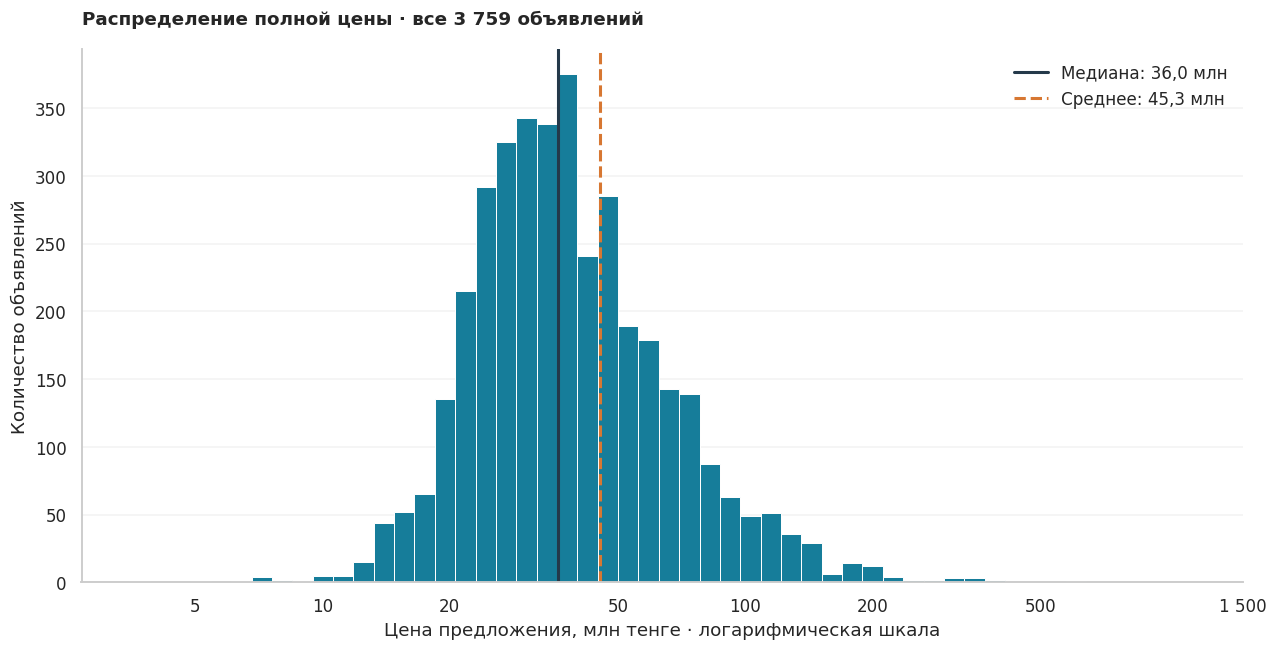

**Вывод:** Медиана — 36,0 млн ₸, среднее — 45,3 млн ₸; дорогие квартиры формируют длинный правый хвост.

In [4]:
fig, ax = plt.subplots(figsize=(11.5, 5.8), layout="constrained")
bins = np.geomspace(prices_mln.min(), prices_mln.max(), 48)
ax.hist(prices_mln, bins=bins, color=TEAL, edgecolor="white", linewidth=0.65)
ax.axvline(price_stats["median"] / 1_000_000, color="#24394A", linewidth=2,
           label=f"Медиана: {ru_number(price_stats['median'] / 1_000_000)} млн")
ax.axvline(price_stats["mean"] / 1_000_000, color=ORANGE, linestyle="--", linewidth=2,
           label=f"Среднее: {ru_number(price_stats['mean'] / 1_000_000)} млн")
ax.set_xscale("log")
ax.set_xticks(PRICE_TICKS)
ax.xaxis.set_major_formatter(FuncFormatter(price_tick))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel="Цена предложения, млн тенге · логарифмическая шкала", ylabel="Количество объявлений")
ax.set_title(f"Распределение полной цены · все {ru_number(n_rows, 0)} объявлений", loc="left", pad=16)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right")
finish_plot(fig, "eda_01_price_distribution.png",
    f"Медиана — {ru_number(price_stats['median'] / 1_000_000)} млн ₸, "
    f"среднее — {ru_number(price_stats['mean'] / 1_000_000)} млн ₸; дорогие квартиры формируют длинный правый хвост.")

## 4. Цена по районам

Внутри каждого «ящика» находятся средние 50% наблюдений, линия внутри — медиана, усы ограничены 1,5 межквартильного размаха, отдельные точки — значения за усами. Эти точки не удаляются. Цена снова показана на логарифмической шкале.

Районы упорядочены по медианной полной цене. Объявления без района выделены серым и не участвуют в выборе самого дорогого/дешёвого района. Сравнение пока не учитывает площадь, число комнат и другие различия квартир.

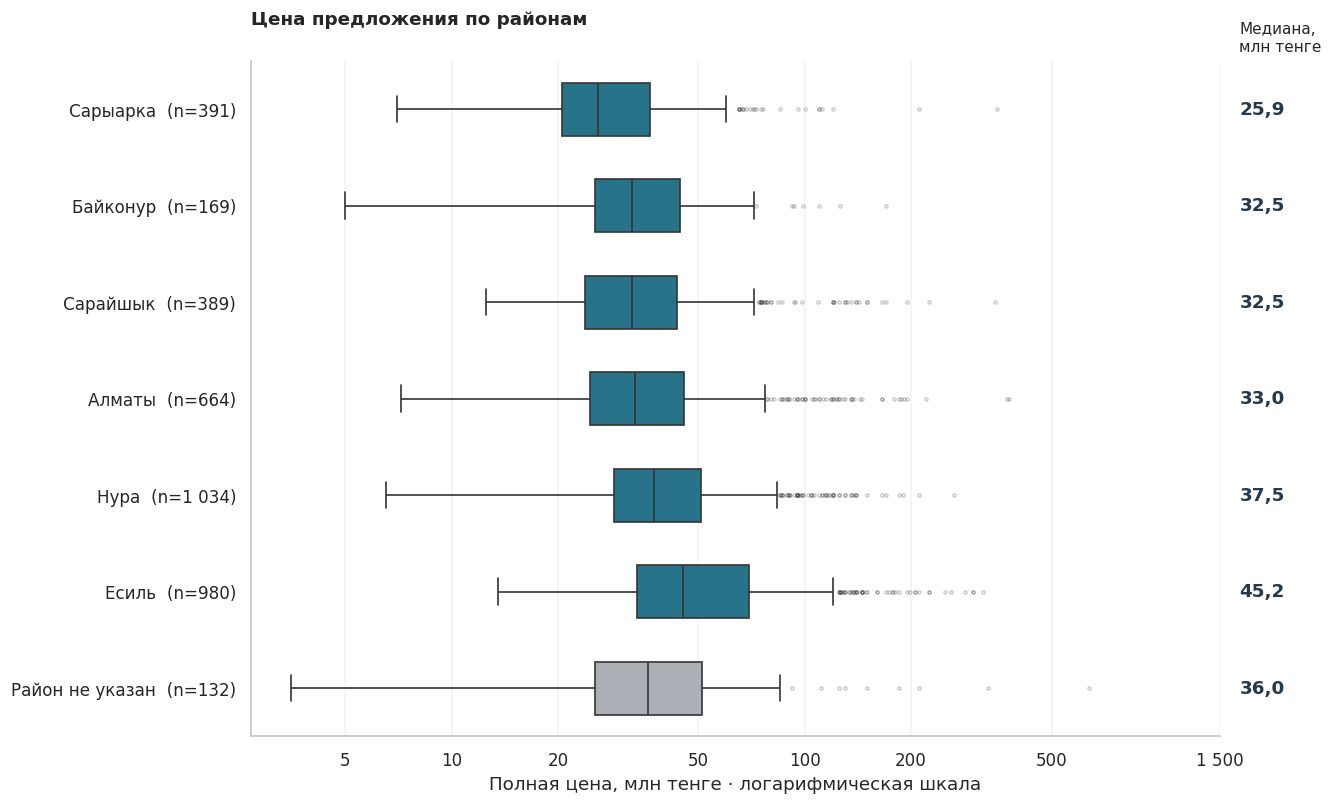

**Вывод:** Наибольшая медиана — Есиль (45,2 млн ₸), наименьшая — Сарыарка (25,9 млн ₸); состав квартир по районам различается.

In [5]:
unknown_district = "Район не указан"
district_data = df.assign(district_label=df["district"].fillna(unknown_district), price_mln=prices_mln)
district_stats = district_data.groupby("district_label").agg(
    n=("price", "size"), median_price=("price", "median"), median_area=("area", "median"),
)
known_districts = district_stats.drop(index=unknown_district, errors="ignore").sort_values("median_price")
order = known_districts.index.tolist()
if unknown_district in district_stats.index:
    order.append(unknown_district)
palette = {name: ("#A8B0B8" if name == unknown_district else TEAL) for name in order}

fig, ax = plt.subplots(figsize=(12, 7.2), layout="constrained")
sns.boxplot(data=district_data, x="price_mln", y="district_label", order=order,
            hue="district_label", hue_order=order, palette=palette, legend=False, dodge=False,
            width=0.55, linewidth=1.1, flierprops={"markersize": 2, "alpha": 0.25}, ax=ax)
ax.set_xscale("log")
ax.set_xticks(PRICE_TICKS)
ax.xaxis.set_major_formatter(FuncFormatter(price_tick))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(range(len(order)), labels=[
    f"{name}  (n={ru_number(district_stats.loc[name, 'n'], 0)})" for name in order
])
for position, name in enumerate(order):
    ax.text(1.02, position, ru_number(district_stats.loc[name, "median_price"] / 1_000_000),
            transform=ax.get_yaxis_transform(), va="center", color="#24394A", fontweight="bold")
ax.text(1.02, 1.015, "Медиана,\nмлн тенге", transform=ax.transAxes, fontsize=10)
ax.set(xlabel="Полная цена, млн тенге · логарифмическая шкала", ylabel="")
ax.set_title("Цена предложения по районам", loc="left", pad=24)
ax.grid(axis="y", visible=False)
highest_district = known_districts["median_price"].idxmax()
lowest_district = known_districts["median_price"].idxmin()
finish_plot(fig, "eda_02_price_by_district.png",
    f"Наибольшая медиана — {highest_district} ({ru_number(known_districts.loc[highest_district, 'median_price'] / 1_000_000)} млн ₸), "
    f"наименьшая — {lowest_district} ({ru_number(known_districts.loc[lowest_district, 'median_price'] / 1_000_000)} млн ₸); состав квартир по районам различается.")

## 5. Связь цены с площадью

Одна точка — одно объявление; прозрачность помогает видеть плотные участки. Показаны все строки и весь диапазон площади, без случайной подвыборки. Цена по вертикали имеет логарифмическую шкалу.

**Pearson r** описывает линейную связь исходных цены и площади, **Spearman ρ** — связь их рангов. Эти коэффициенты не рассчитаны на логарифмах и не являются метриками качества модели или доказательством причинности.

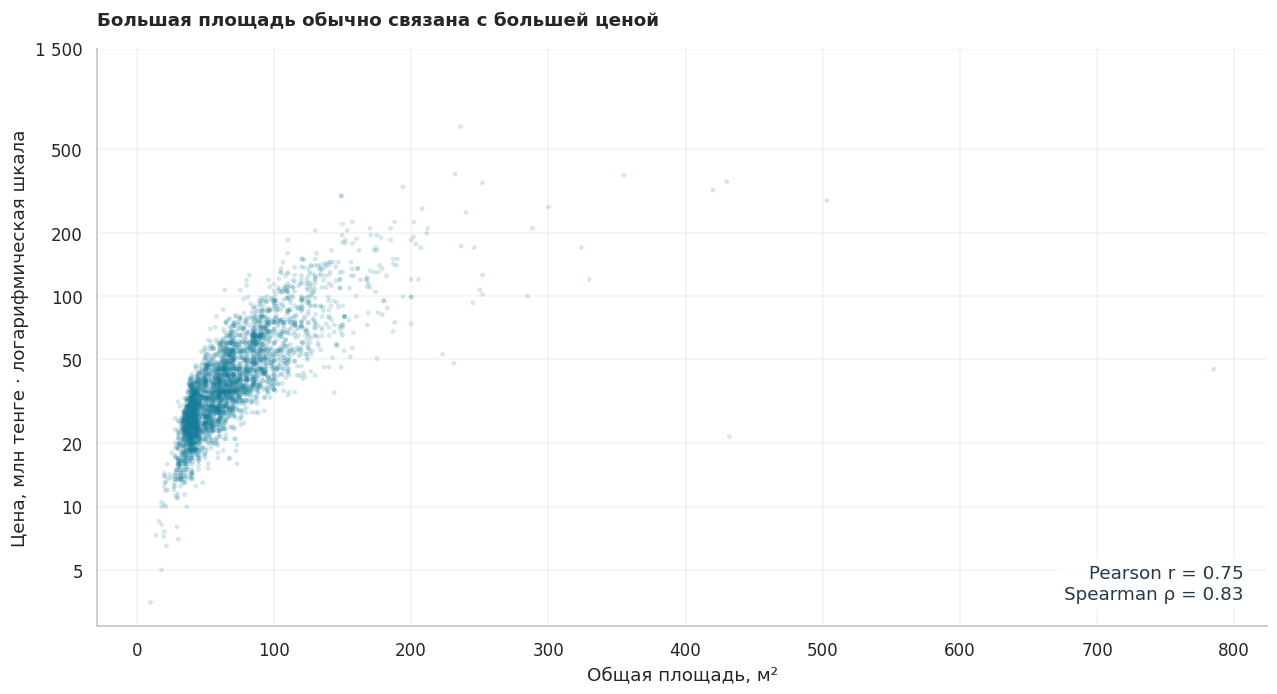

**Вывод:** Связь цены и площади положительная (r=0,75, ρ=0,83), но при одинаковой площади встречаются разные цены.

In [6]:
pearson_area = float(df[["price", "area"]].corr(method="pearson").loc["price", "area"])
# Корреляция рангов равна коэффициенту Спирмена; обучение здесь не требуется.
spearman_area = float(df[["price", "area"]].rank(method="average").corr().loc["price", "area"])
fig, ax = plt.subplots(figsize=(11.5, 6.2), layout="constrained")
ax.scatter(df["area"], prices_mln, s=10, alpha=0.18, color=TEAL, edgecolors="none", rasterized=True)
ax.set_yscale("log")
ax.set_yticks(PRICE_TICKS)
ax.yaxis.set_major_formatter(FuncFormatter(price_tick))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel="Общая площадь, м²", ylabel="Цена, млн тенге · логарифмическая шкала")
ax.set_title("Большая площадь обычно связана с большей ценой", loc="left", pad=16)
ax.text(0.98, 0.04, f"Pearson r = {pearson_area:.2f}\nSpearman ρ = {spearman_area:.2f}",
        transform=ax.transAxes, ha="right", va="bottom", color="#24394A",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
finish_plot(fig, "eda_03_price_vs_area.png",
    f"Связь цены и площади положительная (r={ru_number(pearson_area, 2)}, ρ={ru_number(spearman_area, 2)}), "
    "но при одинаковой площади встречаются разные цены.")

## 6. Корреляции числовых признаков

Матрица Pearson включает цену и пять числовых входных признаков. Район, тип дома и состояние — категории: произвольные числовые коды для них здесь не вводятся. `source_row`, URL, дата и цена за м² также не включаются.

Пропуски исключаются попарно; таблица показывает, сколько наблюдений использовано в связи каждого признака с ценой. Слабая линейная корреляция не означает, что признак бесполезен для нелинейной модели.

,Pearson r с ценой,Пар наблюдений
Площадь,0.752,3759
Комнаты,0.675,3759
Этаж,0.152,3715
Этажность,0.178,3594
Год постройки,0.113,3759


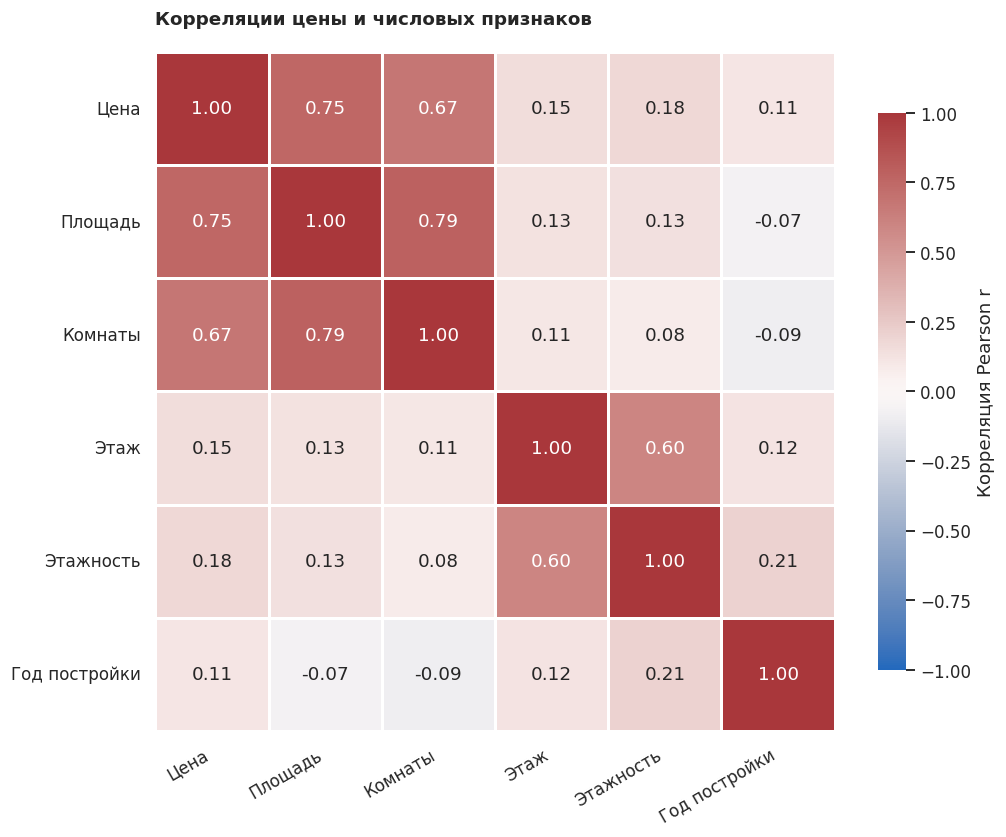

**Вывод:** С ценой сильнее всего связаны площадь (r=0,75) и комнаты (r=0,67); слабая линейная связь остальных признаков не исключает их пользы для модели.

In [7]:
correlations = df[NUMERIC].corr(method="pearson", min_periods=3)
valid = df[NUMERIC].notna().astype("int64")
pair_counts = valid.T @ valid
price_correlations = pd.DataFrame({
    "Pearson r с ценой": correlations.loc["price"].drop("price"),
    "Пар наблюдений": pair_counts.loc["price"].drop("price"),
})
display(price_correlations.rename(index=LABELS).round(3))

fig, ax = plt.subplots(figsize=(9.4, 7.5), layout="constrained")
sns.heatmap(correlations.rename(index=LABELS, columns=LABELS), annot=True, fmt=".2f",
            cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.8,
            cbar_kws={"label": "Корреляция Pearson r", "shrink": 0.82}, ax=ax)
ax.set_title("Корреляции цены и числовых признаков", loc="left", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
strongest = correlations["price"].drop("price").abs().nlargest(2).index.tolist()
strong_text = " и ".join(f"{LABELS[name].lower()} (r={ru_number(correlations.loc['price', name], 2)})" for name in strongest)
finish_plot(fig, "eda_04_correlations.png",
    f"С ценой сильнее всего связаны {strong_text}; слабая линейная связь остальных признаков не исключает их пользы для модели.")

## Как интерпретировать этот срез

- Длинный хвост цены влияет на средние значения и ошибки в тенге. Все очищенные строки показаны без дополнительного удаления дорогих квартир ради графиков или метрик.
- Районные медианы описывают состав мартовской выборки. Они не показывают причинное влияние района и не учитывают различия площади, комнат и других характеристик.
- Пропуски остаются пропусками. В обучении обработка отсутствующих значений и категорий относится к пайплайну, обученному на train; этот ноутбук его не меняет.
- **Это описательный EDA после обучения на всех очищенных строках, включая test.** Графики и корреляции не используются для выбора модели, признаков, гиперпараметров или пересмотра разбиения. Следующую версию модели после новых гипотез нужно проверять на независимых данных.
- Конец марта 2026 года — период по заявлению автора Turarr. Дат сбора по строкам нет; известные даты публикации и скачивания не подтверждают даты конкретных наблюдений.
- Цены отражают предложения одной площадки и состав данного набора. Этот анализ не измеряет изменение рынка относительно января и не подтверждает точность модели на текущую дату.

Обучение моделей и оценка ошибок выполняются отдельными скриптами. В этом ноутбуке модели не обучаются и не выбираются.


In [8]:
# Сохраняем только отчёт и рисунки; исходный и очищенный CSV не изменяем.
summary = {
    "input_file": CLEAN_LISTINGS_PATH.relative_to(project_root).as_posix(),
    "input_sha256": input_hash,
    "rows": n_rows,
    "declared_period": declared_period,
    "active_application_model": "january_2026",
    "declared_period_label": declared_period_label,
    "source_metadata": {
        "manifest": source_metadata_path.relative_to(project_root).as_posix(),
        "dataset_title": source_metadata["dataset_title"],
        "publisher": source_metadata["publisher"],
        "source_page": source_metadata["source_page"],
        "dataset_version": source_metadata["dataset_version"],
        "declared_data_period": source_metadata["declared_data_period"],
        "declared_data_period_source": source_metadata["declared_data_period_source"],
        "raw_sha256": source_metadata["sha256"],
        "row_collection_dates_available": not collection_dates.empty,
    },
    "collected_date_min": collected_date_min,
    "collected_date_max": collected_date_max,
    "price_summary_kzt": price_stats,
    "missing_counts": df[FEATURES].isna().sum().astype(int).to_dict(),
    "missing_percent": (df[FEATURES].isna().mean() * 100).to_dict(),
    "district_summary": district_stats.reset_index().to_dict(orient="records"),
    "price_area_pearson": pearson_area,
    "price_area_spearman": spearman_area,
    "numeric_columns": NUMERIC,
    "pearson_correlations": correlations.to_dict(),
    "pairwise_observations": pair_counts.to_dict(),
    "figures": [f"reports/figures/{name}" for name in (
        "eda_01_price_distribution.png", "eda_02_price_by_district.png",
        "eda_03_price_vs_area.png", "eda_04_correlations.png",
    )],
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "matplotlib": mpl.__version__, "seaborn": sns.__version__},
    "notes": ["All cleaned rows included; no sampling or price-tail trimming.",
              "Descriptive EDA after training; all cleaned March rows including test are included.",
              "The application retains the January model; this notebook reads the staged March dataset.",
              "No model, feature, hyperparameter, or split selection is based on this report.",
              "No imputation, train/test split, or model fitting performed in this notebook.",
              "March 2026 is publisher-declared; no row-level collection dates are available.",
              "Publication and retrieval timestamps are not substituted for observation dates."],
}
(REPORTS_DIR / "eda_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
assert hashlib.sha256(CLEAN_LISTINGS_PATH.read_bytes()).hexdigest() == input_hash
print("Готово: 4 графика и reports/eda_summary.json; очищенный CSV не изменён.")

Готово: 4 графика и reports/eda_summary.json; очищенный CSV не изменён.
